In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os
import json
import random
import shutil
import zipfile
import tarfile
import math
import re
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

SEED = 10623

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Google Drive project directory
PROJECT_DIR = Path("/content/drive/MyDrive/EMMbedding")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset directories
DATA_DIR = Path("/content/data/artcap")
IMAGES_DIR = DATA_DIR / "images"
ANNOTATIONS_DIR = DATA_DIR / "annotations"

# Experiment directories
PREFERENCES_DIR = PROJECT_DIR / "preferences"
E2_DIR = PROJECT_DIR / "E2_random_dpo"
ADAPTER_DIR = E2_DIR / "adapter"
PREDICTIONS_DIR = E2_DIR / "predictions"

for directory in [
    DATA_DIR,
    IMAGES_DIR,
    ANNOTATIONS_DIR,
    PREFERENCES_DIR,
    E2_DIR,
    ADAPTER_DIR,
    PREDICTIONS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Experiment directory:", E2_DIR)

# Confirm GPU
assert torch.cuda.is_available(), "No GPU detected. Select a GPU runtime."

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

assert "A100" in torch.cuda.get_device_name(0), (
    "This notebook was configured for an A100. "
    "Check your Colab GPU runtime before continuing."
)

Mounted at /content/drive
Project directory: /content/drive/MyDrive/EMMbedding
Dataset directory: /content/data/artcap
Experiment directory: /content/drive/MyDrive/EMMbedding/E2_random_dpo
GPU: NVIDIA A100-SXM4-40GB
GPU memory: 39.49 GB


In [2]:
import gdown

ARTCAP_IMAGE_FILE_ID = "1inQ4W-CtNhhfo1vAehSbLgyMPTmltWVa"
KALE_FILE_ID = "1OdPZMQQACgy2OmRsIp3-W-KnD7ATC-hO"

ARTCAP_ARCHIVE = DATA_DIR / "artcap_images_archive"
KALE_ARCHIVE = DATA_DIR / "kale_data.zip"

def download_google_drive(file_id, output_path):
    output_path = Path(output_path)

    if output_path.exists() and output_path.stat().st_size > 0:
        print(f"Already downloaded: {output_path}")
        return

    url = f"https://drive.google.com/uc?id={file_id}"
    gdown.download(url, str(output_path), quiet=False, fuzzy=True)

    if not output_path.exists() or output_path.stat().st_size == 0:
        raise RuntimeError(f"Download failed: {output_path}")

download_google_drive(ARTCAP_IMAGE_FILE_ID, ARTCAP_ARCHIVE)
download_google_drive(KALE_FILE_ID, KALE_ARCHIVE)

print("ArtCap archive:", ARTCAP_ARCHIVE)
print("KALE archive:", KALE_ARCHIVE)

Downloading...
From (original): https://drive.google.com/uc?id=1inQ4W-CtNhhfo1vAehSbLgyMPTmltWVa
From (redirected): https://drive.google.com/uc?id=1inQ4W-CtNhhfo1vAehSbLgyMPTmltWVa&confirm=t&uuid=6abbe28a-02d7-4393-98a3-7436e3fa48ea
To: /content/data/artcap/artcap_images_archive
100%|██████████| 597M/597M [00:11<00:00, 51.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1OdPZMQQACgy2OmRsIp3-W-KnD7ATC-hO
To: /content/data/artcap/kale_data.zip
100%|██████████| 13.5M/13.5M [00:00<00:00, 233MB/s]

ArtCap archive: /content/data/artcap/artcap_images_archive
KALE archive: /content/data/artcap/kale_data.zip


In [4]:
def extract_archive(archive_path, destination):
    archive_path = Path(archive_path)
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)

    if zipfile.is_zipfile(archive_path):
        with zipfile.ZipFile(archive_path, "r") as z:
            z.extractall(destination)
        print(f"Extracted ZIP: {archive_path}")

    elif tarfile.is_tarfile(archive_path):
        with tarfile.open(archive_path, "r:*") as t:
            t.extractall(destination)
        print(f"Extracted TAR: {archive_path}")

    else:
        raise ValueError(
            f"Unsupported archive format: {archive_path}. "
            "Inspect the downloaded file before proceeding."
        )

# Extract KALE annotations
# Extract KALE annotations
KALE_EXTRACT_DIR = DATA_DIR / "kale"

if not KALE_EXTRACT_DIR.exists() or not any(KALE_EXTRACT_DIR.iterdir()):
    extract_archive(KALE_ARCHIVE, KALE_EXTRACT_DIR)
else:
    print("KALE annotations already extracted.")

# Extract ArtCap images
IMAGE_EXTRACT_DIR = DATA_DIR / "image_archive"

if not IMAGE_EXTRACT_DIR.exists() or not any(IMAGE_EXTRACT_DIR.iterdir()):
    extract_archive(ARTCAP_ARCHIVE, IMAGE_EXTRACT_DIR)
else:
    print("ArtCap images already extracted.")

Extracted ZIP: /content/data/artcap/kale_data.zip
Extracted ZIP: /content/data/artcap/artcap_images_archive


In [5]:
TRAIN_VAL_FILENAME = "artcap_train_val.json"
TEST_FILENAME = "artcap_test.json"

def find_file(root, filename):
    matches = list(Path(root).rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename} under {root}. "
            "Inspect the extracted archive structure."
        )
    if len(matches) > 1:
        print(f"Found multiple copies of {filename}; using:", matches[0])
    return matches[0]

TRAIN_VAL_JSON = find_file(KALE_EXTRACT_DIR, TRAIN_VAL_FILENAME)
TEST_JSON = find_file(KALE_EXTRACT_DIR, TEST_FILENAME)

# Locate the image directory. Prefer a directory named "images".
image_dirs = [
    p for p in IMAGE_EXTRACT_DIR.rglob("*")
    if p.is_dir() and p.name.lower() == "images"
]

if image_dirs:
    SOURCE_IMAGES_DIR = image_dirs[0]
else:
    # Fallback: use the extracted root and search recursively for images.
    SOURCE_IMAGES_DIR = IMAGE_EXTRACT_DIR

print("Train/val annotation:", TRAIN_VAL_JSON)
print("Test annotation:", TEST_JSON)
print("Image search directory:", SOURCE_IMAGES_DIR)

# Count images found
image_files = [
    p for p in SOURCE_IMAGES_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Image files found:", len(image_files))
print("Example image files:", image_files[:5])

Train/val annotation: /content/data/artcap/kale/data/ArtCap/artcap_train_val.json
Test annotation: /content/data/artcap/kale/data/ArtCap/artcap_test.json
Image search directory: /content/data/artcap/image_archive/images
Image files found: 3606
Example image files: [PosixPath('/content/data/artcap/image_archive/images/3477.jpg'), PosixPath('/content/data/artcap/image_archive/images/14503.jpg'), PosixPath('/content/data/artcap/image_archive/images/21927.jpg'), PosixPath('/content/data/artcap/image_archive/images/38941.jpg'), PosixPath('/content/data/artcap/image_archive/images/94351.jpg')]


In [6]:
with open(TRAIN_VAL_JSON, "r") as f:
    train_val_raw = json.load(f)

with open(TEST_JSON, "r") as f:
    test_raw = json.load(f)

print("Train/val top-level type:", type(train_val_raw))
print("Test top-level type:", type(test_raw))

print("\nTrain/val example:")
print(json.dumps(
    train_val_raw[:1] if isinstance(train_val_raw, list) else train_val_raw,
    indent=2
)[:4000])

print("\nTest example:")
print(json.dumps(
    test_raw[:1] if isinstance(test_raw, list) else test_raw,
    indent=2
)[:4000])

Train/val top-level type: <class 'list'>
Test top-level type: <class 'list'>

Train/val example:
[
  [
    "16922.jpg",
    [
      "a child holding a doll is also holding her face",
      "girl sitting in an armchair with chin in hand with the doll",
      "a young girl wearing a blue shirt is holding a doll lays in a bed",
      "a girl thinks while sitting in a bed holding a doll",
      "a woman is sitting in a chair with a doll"
    ]
  ]
]

Test example:
[
  [
    "34256.jpg",
    [
      "a painter was copying a model sleeping with a book in her arms",
      "a woman looking at a book in front of a mirror",
      "a girl with a man reading at a drawing table",
      "a painter is sitting in a chair painting",
      "an artist is drawing a woman reading a book"
    ]
  ]
]


In [7]:
def get_first(d, keys, default=None):
    for key in keys:
        if key in d and d[key] is not None:
            return d[key]
    return default


def normalize_annotation(data):
    """
    Supports:
      1. [filename, [caption1, caption2, ...]]
      2. [{"image_id": ..., "captions": [...]}]
      3. One record per caption, with image_id and caption fields.
      4. Dictionaries containing images or annotations.
    """
    result = {}

    if isinstance(data, dict):
        if "images" in data:
            data = data["images"]
        elif "annotations" in data:
            data = data["annotations"]
        else:
            data = list(data.values())

    if not isinstance(data, list):
        raise ValueError(f"Unexpected annotation type: {type(data)}")

    # Format from your example: [filename, [captions]]
    if data and isinstance(data[0], (list, tuple)):
        for item in data:
            if len(item) != 2:
                continue

            image_id, captions = item

            if isinstance(captions, list):
                image_id = Path(str(image_id)).stem
                result[str(image_id)] = {
                    "references": [
                        str(c) for c in captions if c
                    ],
                    "caption_ids": [],
                }

        if result:
            return result

    # Dictionary records.
    for record in data:
        if not isinstance(record, dict):
            continue

        image_id = get_first(
            record,
            ["image_id", "id", "img_id", "filename", "image"]
        )

        captions = get_first(
            record,
            ["references", "captions", "sentences", "annotations"]
        )

        if image_id is not None and isinstance(captions, list):
            refs = []
            caption_ids = []

            for caption in captions:
                if isinstance(caption, str):
                    refs.append(caption)
                elif isinstance(caption, dict):
                    caption_text = get_first(
                        caption, ["caption", "text", "sentence"]
                    )
                    if caption_text:
                        refs.append(caption_text)
                        caption_ids.append(
                            get_first(caption, ["id", "caption_id"])
                        )

            result[Path(str(image_id)).stem] = {
                "references": refs,
                "caption_ids": caption_ids,
            }

    # One record per caption.
    if not result:
        grouped = defaultdict(lambda: {
            "references": [],
            "caption_ids": [],
        })

        for record in data:
            if not isinstance(record, dict):
                continue

            image_id = get_first(
                record, ["image_id", "img_id", "image"]
            )
            caption = get_first(
                record, ["caption", "text", "sentence"]
            )

            if image_id is not None and caption:
                image_id = Path(str(image_id)).stem
                grouped[image_id]["references"].append(caption)
                grouped[image_id]["caption_ids"].append(
                    get_first(record, ["id", "caption_id"])
                )

        result = dict(grouped)

    if not result:
        raise ValueError(
            "Could not parse annotations. Inspect the JSON structure."
        )

    return result


train_val_annotations = normalize_annotation(train_val_raw)
test_annotations = normalize_annotation(test_raw)

print("Train/val paintings:", len(train_val_annotations))
print("Test paintings:", len(test_annotations))

example_id = next(iter(train_val_annotations))
print("\nExample image ID:", example_id)
print("Example references:")
for caption in train_val_annotations[example_id]["references"]:
    print("-", caption)

Train/val paintings: 2524
Test paintings: 1082

Example image ID: 16922
Example references:
- a child holding a doll is also holding her face
- girl sitting in an armchair with chin in hand with the doll
- a young girl wearing a blue shirt is holding a doll lays in a bed
- a girl thinks while sitting in a bed holding a doll
- a woman is sitting in a chair with a doll


Train paintings: 2271
Validation paintings: 253
Test paintings: 1082
Total rows: 3606
Train: 2271
Validation: 253
Test: 1082
Saved: /content/drive/MyDrive/EMMbedding/captions.jsonl


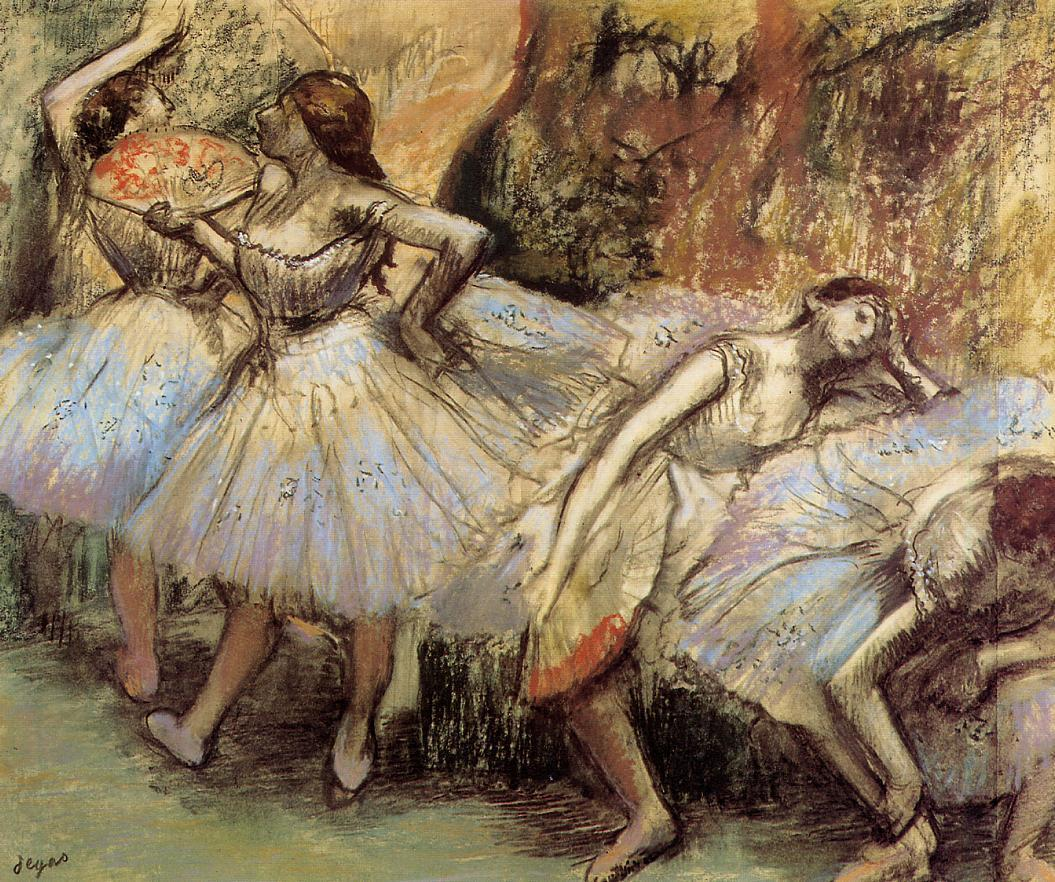

['several dancing girls in full knee-length dresses and two are holding fans', 'it depicts the dancing and narrative performance of people', 'multiple women are standing around in white dresses', 'ballerinas in tutus and toe shoes stretch and wait backstage', 'some ballerinas dressed in white dresses with two of them holding fans']


In [8]:
from sklearn.model_selection import train_test_split

train_val_ids = list(train_val_annotations.keys())

train_ids, val_ids = train_test_split(
    train_val_ids,
    test_size=0.1,
    random_state=SEED,
)

train_ids = set(train_ids)
val_ids = set(val_ids)
test_ids = set(test_annotations.keys())

print("Train paintings:", len(train_ids))
print("Validation paintings:", len(val_ids))
print("Test paintings:", len(test_ids))


# Build a lookup table for image files.
image_lookup = {}

for path in SOURCE_IMAGES_DIR.rglob("*"):
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        image_lookup[path.stem] = path


def resolve_image_path(image_id):
    image_id = str(image_id)

    # Exact filename stem match.
    if image_id in image_lookup:
        return image_lookup[image_id]

    # Try integer-normalized IDs, e.g. "0034256" vs "34256".
    try:
        normalized_id = str(int(image_id))
        if normalized_id in image_lookup:
            return image_lookup[normalized_id]
    except ValueError:
        pass

    raise FileNotFoundError(f"Image not found for image_id={image_id}")


def make_rows(annotation_dict, split):
    rows = []

    for image_id, record in annotation_dict.items():
        image_path = resolve_image_path(image_id)
        references = record["references"]

        if len(references) != 5:
            raise ValueError(
                f"Expected 5 references for image {image_id}, "
                f"found {len(references)}"
            )

        rows.append({
            "image_id": str(image_id),
            "image_path": str(image_path),
            "split": split,
            "references": references,
            "caption_ids": record.get("caption_ids", []),
        })

    return rows


train_rows = make_rows(
    {k: train_val_annotations[k] for k in train_ids},
    "train"
)

val_rows = make_rows(
    {k: train_val_annotations[k] for k in val_ids},
    "val"
)

test_rows = make_rows(test_annotations, "test")

all_rows = train_rows + val_rows + test_rows

print("Total rows:", len(all_rows))
print("Train:", len(train_rows))
print("Validation:", len(val_rows))
print("Test:", len(test_rows))

# Save the canonical dataset metadata.
CAPTIONS_JSONL = PROJECT_DIR / "captions.jsonl"

with open(CAPTIONS_JSONL, "w") as f:
    for row in all_rows:
        f.write(json.dumps(row) + "\n")

print("Saved:", CAPTIONS_JSONL)

# Verify a sample image can be opened.
sample = train_rows[0]
display(Image.open(sample["image_path"]).convert("RGB"))
print(sample["references"])

In [9]:
JUDGE_PAIRS_CANDIDATES = [
    PROJECT_DIR / "judge_pairs.jsonl",
    PREFERENCES_DIR / "judge_pairs.jsonl",
    DATA_DIR / "preferences" / "judge_pairs.jsonl",
    Path("/content/data/preferences/judge_pairs.jsonl"),
    Path("data/preferences/judge_pairs.jsonl"),
]

JUDGE_PAIRS_PATH = next(
    (p for p in JUDGE_PAIRS_CANDIDATES if p.exists()),
    None
)

if JUDGE_PAIRS_PATH is None:
    from google.colab import files

    print("Upload your judge_pairs.jsonl file.")
    uploaded = files.upload()

    if "judge_pairs.jsonl" not in uploaded:
        raise FileNotFoundError(
            "Please upload a file named judge_pairs.jsonl."
        )

    JUDGE_PAIRS_PATH = PROJECT_DIR / "judge_pairs.jsonl"
    with open(JUDGE_PAIRS_PATH, "wb") as f:
        f.write(uploaded["judge_pairs.jsonl"])

print("Using:", JUDGE_PAIRS_PATH)

judge_pairs = []

with open(JUDGE_PAIRS_PATH, "r") as f:
    for line in f:
        if line.strip():
            judge_pairs.append(json.loads(line))

print("Total judge pairs:", len(judge_pairs))
print("Example metadata:", {
    key: judge_pairs[0].get(key)
    for key in ["pair_id", "image_id", "split"]
})

Upload your judge_pairs.jsonl file.


Saving judge_pairs.jsonl to judge_pairs.jsonl
Using: /content/drive/MyDrive/EMMbedding/judge_pairs.jsonl
Total judge pairs: 5037
Example metadata: {'pair_id': '38490:1', 'image_id': '38490', 'split': 'train'}


In [11]:
# Count judge pairs per painting and split.
# We use ONLY the counts, never the judge's caption preferences.

target_pair_counts = Counter(
    (str(row["image_id"]), row["split"])
    for row in judge_pairs
)

artcap_lookup = {
    (str(row["image_id"]), row["split"]): row
    for row in train_rows + val_rows
}

random_rng = random.Random(SEED)

random_pairs = []
insufficient_pairs = []

for (image_id, split), requested_count in sorted(target_pair_counts.items()):

    key = (image_id, split)

    if key not in artcap_lookup:
        raise KeyError(f"Missing ArtCap painting: {key}")

    references = artcap_lookup[key]["references"]

    # Generate pairs using caption indices, not caption strings.
    possible_pairs = list(combinations(range(len(references)), 2))

    # Remove pairs where both captions have identical text.
    valid_pairs = [
        (i, j)
        for i, j in possible_pairs
        if references[i].strip() != references[j].strip()
    ]

    if len(valid_pairs) < requested_count:
        insufficient_pairs.append({
            "image_id": image_id,
            "split": split,
            "requested": requested_count,
            "available": len(valid_pairs),
        })
        continue

    sampled_pairs = random_rng.sample(
        valid_pairs,
        k=requested_count
    )

    for pair_number, (i, j) in enumerate(sampled_pairs, start=1):

        caption_a = references[i]
        caption_b = references[j]

        # Random preference direction.
        if random_rng.random() < 0.5:
            chosen, rejected = caption_a, caption_b
        else:
            chosen, rejected = caption_b, caption_a

        random_pairs.append({
            "pair_id": f"{image_id}:random:{pair_number}",
            "image_id": image_id,
            "split": split,
            "image_path": artcap_lookup[key]["image_path"],
            "chosen": chosen,
            "rejected": rejected,
        })


# Check for paintings that did not have enough distinct captions.
if insufficient_pairs:
    print("Paintings with insufficient distinct caption pairs:")
    display(pd.DataFrame(insufficient_pairs))

    raise ValueError(
        "Some paintings do not have enough distinct caption pairs. "
        "Review the diagnostics above."
    )


# Verify no identical chosen/rejected captions.
assert all(
    row["chosen"].strip() != row["rejected"].strip()
    for row in random_pairs
)

# Verify pair counts exactly match judge-pair counts.
generated_pair_counts = Counter(
    (str(row["image_id"]), row["split"])
    for row in random_pairs
)

assert generated_pair_counts == target_pair_counts

# Save random pairs.
RANDOM_PAIRS_PATH = PREFERENCES_DIR / "random_pairs.jsonl"

with open(RANDOM_PAIRS_PATH, "w") as f:
    for row in random_pairs:
        f.write(json.dumps(row) + "\n")

print("Generated random pairs:", len(random_pairs))
print("Train pairs:", sum(r["split"] == "train" for r in random_pairs))
print("Validation pairs:", sum(r["split"] == "val" for r in random_pairs))
print("Saved:", RANDOM_PAIRS_PATH)

print("\nExample:")
print(json.dumps(random_pairs[0], indent=2))

Generated random pairs: 5037
Train pairs: 4532
Validation pairs: 505
Saved: /content/drive/MyDrive/EMMbedding/preferences/random_pairs.jsonl

Example:
{
  "pair_id": "100020:random:1",
  "image_id": "100020",
  "split": "train",
  "image_path": "/content/data/artcap/image_archive/images/100020.jpg",
  "chosen": "the image summarize the grand ma",
  "rejected": "old lady reading a book"
}


Training preference pairs: 4532
Validation preference pairs: 505
Dataset({
    features: ['image', 'prompt', 'chosen', 'rejected', 'image_id'],
    num_rows: 4532
})

Example dataset row:
{'image_id': '100020', 'prompt': [{'content': 'Describe the visual content of this painting in one concise, informative sentence.\n\nFocus on:\n- The people, objects, and subjects depicted.\n- Their actions and spatial relationships.\n- Important colors, visual attributes, and setting.\n\nOnly describe details that are visually supported by the image.\nDo not speculate about the artist, historical context, or symbolic meaning.\n\nReturn only the caption.', 'role': 'user'}], 'chosen': [{'content': 'the image summarize the grand ma', 'role': 'assistant'}], 'rejected': [{'content': 'old lady reading a book', 'role': 'assistant'}]}


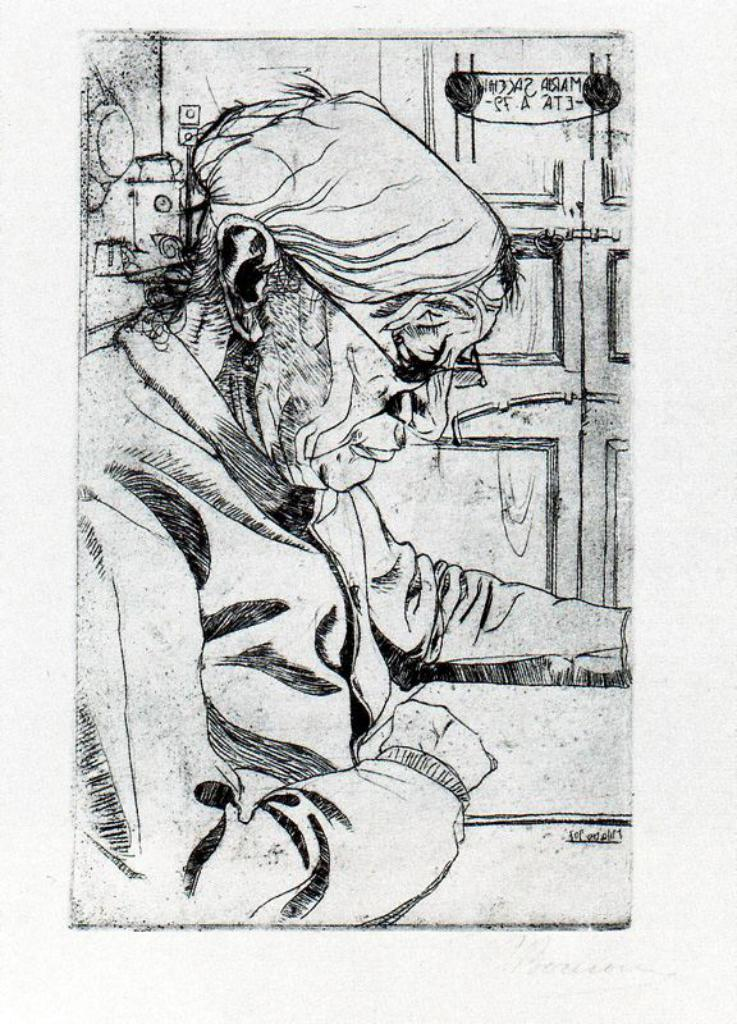

In [12]:
PROMPT = """Describe the visual content of this painting in one concise, informative sentence.

Focus on:
- The people, objects, and subjects depicted.
- Their actions and spatial relationships.
- Important colors, visual attributes, and setting.

Only describe details that are visually supported by the image.
Do not speculate about the artist, historical context, or symbolic meaning.

Return only the caption."""


train_pairs = [
    row for row in random_pairs
    if row["split"] == "train"
]

val_pairs = [
    row for row in random_pairs
    if row["split"] == "val"
]

print("Training preference pairs:", len(train_pairs))
print("Validation preference pairs:", len(val_pairs))

assert len(train_pairs) > 0, "No training pairs found."


# Hugging Face datasets + image feature.
from datasets import Dataset, Image as HFImage

def to_hf_record(row):
    return {
        "image": {
            "path": row["image_path"],
            "bytes": None,
        },
        "prompt": [
            {
                "role": "user",
                "content": PROMPT,
            }
        ],
        "chosen": [
            {
                "role": "assistant",
                "content": row["chosen"],
            }
        ],
        "rejected": [
            {
                "role": "assistant",
                "content": row["rejected"],
            }
        ],
        "image_id": str(row["image_id"]),
    }


train_dataset = Dataset.from_list([
    to_hf_record(row) for row in train_pairs
])

train_dataset = train_dataset.cast_column(
    "image",
    HFImage()
)

print(train_dataset)
print("\nExample dataset row:")
print({
    "image_id": train_dataset[0]["image_id"],
    "prompt": train_dataset[0]["prompt"],
    "chosen": train_dataset[0]["chosen"],
    "rejected": train_dataset[0]["rejected"],
})

display(train_dataset[0]["image"].convert("RGB"))

In [13]:
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=224 * 224,
    max_pixels=768 * 768,
)

# Left padding is commonly used for decoder-only generation.
if hasattr(processor, "tokenizer"):
    processor.tokenizer.padding_side = "left"

    if processor.tokenizer.pad_token is None:
        processor.tokenizer.pad_token = processor.tokenizer.eos_token


model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16,
    low_cpu_mem_usage=True,
)

model.config.use_cache = False

print("Loaded:", MODEL_ID)
print("Model dtype:", next(model.parameters()).dtype)

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Loaded: Qwen/Qwen3-VL-4B-Instruct
Model dtype: torch.bfloat16


In [14]:
from peft import LoraConfig
import torch.nn as nn

# Freeze the vision encoder and visual merger/projector.
frozen_visual_params = 0

for name, param in model.named_parameters():
    if "visual" in name.lower():
        param.requires_grad = False
        frozen_visual_params += param.numel()

print("Frozen visual parameters:", f"{frozen_visual_params:,}")


# LoRA targets only language-model projection layers.
target_modules = (
    r".*language_model.*"
    r"(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)$"
)

# Verify the regex matches actual language-model linear layers.
matching_modules = [
    name for name, module in model.named_modules()
    if isinstance(module, nn.Linear) and re.fullmatch(target_modules, name)
]

print("LoRA target modules found:", len(matching_modules))
print("Examples:", matching_modules[:10])

if not matching_modules:
    print("\nLinear module names containing q_proj:")
    print([
        name for name, module in model.named_modules()
        if isinstance(module, nn.Linear) and "q_proj" in name
    ][:20])

    raise RuntimeError(
        "The LoRA target regex did not match any modules. "
        "Inspect the printed module names and update target_modules."
    )


lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=target_modules,
)

print("LoRA configuration:")
print(lora_config)

Frozen visual parameters: 415,347,712
LoRA target modules found: 252
Examples: ['model.language_model.layers.0.self_attn.q_proj', 'model.language_model.layers.0.self_attn.k_proj', 'model.language_model.layers.0.self_attn.v_proj', 'model.language_model.layers.0.self_attn.o_proj', 'model.language_model.layers.0.mlp.gate_proj', 'model.language_model.layers.0.mlp.up_proj', 'model.language_model.layers.0.mlp.down_proj', 'model.language_model.layers.1.self_attn.q_proj', 'model.language_model.layers.1.self_attn.k_proj', 'model.language_model.layers.1.self_attn.v_proj']
LoRA configuration:
LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.21.2', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules='.*language_model.*(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)$', exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, i

In [16]:
!pip install trl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 11.0 MB/s  0:00:00


In [17]:
from trl.trainer.dpo_trainer import DataCollatorForVisionPreference

vision_collator = DataCollatorForVisionPreference(
    processor=processor,
    max_length=None,
)

smoke_batch = vision_collator([
    dict(train_dataset[0])
])

print("Batch keys:", smoke_batch.keys())

for key, value in smoke_batch.items():
    if torch.is_tensor(value):
        print(key, tuple(value.shape), value.dtype)
    else:
        print(key, type(value))

assert "input_ids" in smoke_batch
assert "pixel_values" in smoke_batch or "image_grid_thw" in smoke_batch

print("\nMultimodal preference collator smoke test passed.")

Batch keys: KeysView({'input_ids': tensor([[151644,    872,    198,  ...,   7491, 151645,    198],
        [151644,    872,    198,  ..., 151645,    198, 151643]]), 'attention_mask': tensor([[1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 1, 1, 0]]), 'mm_token_type_ids': tensor([[0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0]]), 'pixel_values': tensor([[0.9608, 0.9529, 0.9294,  ..., 0.9294, 0.9373, 0.9373],
        [0.9059, 0.9137, 0.9373,  ..., 0.9373, 0.9686, 0.9843],
        [0.9137, 0.9216, 0.9294,  ..., 0.9608, 0.9294, 0.9216],
        ...,
        [0.9137, 0.9137, 0.9373,  ..., 0.9216, 0.8980, 0.8980],
        [0.9373, 0.9373, 0.9451,  ..., 0.9294, 0.9373, 0.9373],
        [0.9373, 0.9686, 0.9922,  ..., 0.8745, 0.8745, 0.8824]]), 'image_grid_thw': tensor([[ 1, 56, 40],
        [ 1, 56, 40]]), 'completion_mask': tensor([[0, 0, 0,  ..., 1, 1, 1],
        [0, 0, 0,  ..., 1, 1, 0]])})
input_ids (2, 652) torch.int64
attention_mask (2, 652) torch.int64
mm_token_type_ids (2

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


In [24]:
from trl import DPOConfig, DPOTrainer

NUM_EPOCHS = 1
MICRO_BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 8
LEARNING_RATE = 5e-6
DPO_BETA = 0.1

effective_batch_size = (
    MICRO_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
)

estimated_optimizer_steps = math.ceil(
    len(train_dataset) / effective_batch_size
) * NUM_EPOCHS

print("Training pairs:", len(train_dataset))
print("Effective batch size:", effective_batch_size)
print("Estimated optimizer steps:", estimated_optimizer_steps)


training_args = DPOConfig(
    output_dir=str(E2_DIR / "checkpoints"),

    num_train_epochs=NUM_EPOCHS,

    per_device_train_batch_size=MICRO_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

    learning_rate=LEARNING_RATE,
    beta=DPO_BETA,
    loss_type="sigmoid",

    lr_scheduler_type="cosine",
    warmup_steps=int(0.05 * estimated_optimizer_steps),  # 28 steps

    optim="adamw_torch",
    max_grad_norm=0.3,

    bf16=True,
    fp16=False,
    tf32=True,

    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={
        "use_reentrant": False
    },

    # Do not truncate image tokens in the VLM inputs.
    max_length=None,

    logging_steps=10,
    save_strategy="epoch",
    save_total_limit=2,

    # Keep image and metadata columns available to the collator.
    remove_unused_columns=False,
    dataloader_num_workers=0,

    report_to="none",

    seed=SEED,
    data_seed=SEED,
)

Training pairs: 4532
Effective batch size: 8
Estimated optimizer steps: 567


In [25]:
!pip install -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 58.9 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [28]:
training_args = DPOConfig(
    output_dir=str(E2_DIR / "checkpoints"),
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=MICRO_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=LEARNING_RATE,
    beta=DPO_BETA,
    loss_type="sigmoid",
    lr_scheduler_type="cosine",
    warmup_steps=int(0.05 * estimated_optimizer_steps),  # Replaces warmup_ratio
    optim="adamw_torch",
    max_grad_norm=0.3,
    bf16=True,
    fp16=False,
    tf32=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    max_length=None,
    logging_steps=10,
    save_strategy="epoch",
    save_total_limit=2,
    remove_unused_columns=False,
    dataloader_num_workers=0,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
)

trainer = DPOTrainer(
    model=model,
    ref_model=None,
    args=training_args,
    train_dataset=train_dataset,
    processing_class=processor,
    peft_config=lora_config,
    data_collator=vision_collator,
)

print("DPO trainer initialized.")

W1121 01:00:12.985000 886 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


DPO trainer initialized.


In [29]:
torch.cuda.empty_cache()

train_result = trainer.train()

print("\nTraining complete.")
print(train_result)

# Save adapter and processor.
trainer.save_model(str(ADAPTER_DIR))
processor.save_pretrained(str(ADAPTER_DIR))

# Save training metrics.
training_metrics = train_result.metrics

with open(E2_DIR / "training_metrics.json", "w") as f:
    json.dump(training_metrics, f, indent=2, default=str)

print("Adapter saved to:", ADAPTER_DIR)
print("Training metrics saved.")

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Step,Training Loss
10,0.691586
20,0.695215
30,0.698091
40,0.689673
50,0.700912
60,0.692963
70,0.691141
80,0.695532
90,0.698941
100,0.693058


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(



Training complete.
TrainOutput(global_step=567, training_loss=0.6941809494449138, metrics={'train_runtime': 4427.0785, 'train_samples_per_second': 1.024, 'train_steps_per_second': 0.128, 'total_flos': 1.3786083054672077e+17, 'train_loss': 0.6941809494449138, 'entropy': 0.8353608402495201, 'num_tokens': 5613143.0, 'logits/chosen': 0.8574835222847675, 'logits/rejected': 1.219351483331875, 'mean_token_accuracy': 0.36551415203855586, 'rewards/chosen': 0.03210260745925972, 'rewards/rejected': 0.03470300621568011, 'rewards/accuracies': 0.4807692307692308, 'rewards/margins': -0.0026003988280605813, 'logps/chosen': -94.9733811891996, 'logps/rejected': -93.57614575899564, 'epoch': 1.0})
Adapter saved to: /content/drive/MyDrive/EMMbedding/E2_random_dpo/adapter
Training metrics saved.


In [30]:
print(json.dumps(training_metrics, indent=2, default=str))

experiment_config = {
    "experiment": "E2_random_dpo",
    "model_id": MODEL_ID,
    "seed": SEED,
    "epochs": NUM_EPOCHS,
    "micro_batch_size": MICRO_BATCH_SIZE,
    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "effective_batch_size": effective_batch_size,
    "learning_rate": LEARNING_RATE,
    "dpo_beta": DPO_BETA,
    "loss_type": "sigmoid",
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "vision_encoder_frozen": True,
    "train_pairs": len(train_pairs),
    "validation_pairs": len(val_pairs),
    "test_images": len(test_rows),
    "estimated_optimizer_steps": estimated_optimizer_steps,
}

with open(E2_DIR / "experiment_config.json", "w") as f:
    json.dump(experiment_config, f, indent=2)

print("Experiment configuration saved.")

{
  "train_runtime": 4427.0785,
  "train_samples_per_second": 1.024,
  "train_steps_per_second": 0.128,
  "total_flos": 1.3786083054672077e+17,
  "train_loss": 0.6941809494449138,
  "entropy": 0.8353608402495201,
  "num_tokens": 5613143.0,
  "logits/chosen": 0.8574835222847675,
  "logits/rejected": 1.219351483331875,
  "mean_token_accuracy": 0.36551415203855586,
  "rewards/chosen": 0.03210260745925972,
  "rewards/rejected": 0.03470300621568011,
  "rewards/accuracies": 0.4807692307692308,
  "rewards/margins": -0.0026003988280605813,
  "logps/chosen": -94.9733811891996,
  "logps/rejected": -93.57614575899564,
  "epoch": 1.0
}
Experiment configuration saved.


In [36]:
from peft import PeftModel

# del trainer
# del model
torch.cuda.empty_cache()

base_model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16,
    low_cpu_mem_usage=True,
)

inference_model = PeftModel.from_pretrained(
    base_model,
    str(ADAPTER_DIR),
).to("cuda")

inference_model.eval()
inference_model.config.use_cache = True

print("Loaded trained E2 adapter.")

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Loaded trained E2 adapter.


In [38]:
inference_model = inference_model.to("cuda")
print("Inference device:", inference_model.device)

Inference device: cuda:0


In [40]:
BATCH_SIZE = 16
MAX_NEW_TOKENS = 128
SAVE_EVERY = 32

PREDICTIONS_CSV = PREDICTIONS_DIR / "e2_random_dpo_predictions.csv"

# Ensure model is on GPU and in eval mode
inference_model = inference_model.to("cuda")
inference_model.eval()
print("Model device:", next(inference_model.parameters()).device)


def load_resized_image(image_path, max_side=768):
    img = Image.open(image_path).convert("RGB")
    img.thumbnail((max_side, max_side), Image.Resampling.LANCZOS)
    return img


def generate_captions_batch(image_paths):
    batch_messages = [
        [
            {
                "role": "user",
                "content": [
                    {"type": "image", "image": load_resized_image(p)},
                    {"type": "text", "text": PROMPT},
                ],
            }
        ]
        for p in image_paths
    ]

    inputs = processor.apply_chat_template(
        batch_messages,
        tokenize=True,
        add_generation_prompt=True,
        padding=True,
        return_dict=True,
        return_tensors="pt",
    ).to("cuda")

    with torch.inference_mode():
        generated_ids = inference_model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
        )

    generated_ids_trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(inputs["input_ids"], generated_ids)
    ]

    return [
        text.strip()
        for text in processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )
    ]


# Resume if a previous run already saved some predictions.
if PREDICTIONS_CSV.exists():
    predictions_df = pd.read_csv(PREDICTIONS_CSV)
    completed_ids = set(predictions_df["image_id"].astype(str))
    predictions = predictions_df.to_dict("records")
    print("Resuming from", len(completed_ids), "existing predictions.")
else:
    completed_ids = set()
    predictions = []

remaining_rows = [
    row for row in test_rows if str(row["image_id"]) not in completed_ids
]
print(f"Remaining images: {len(remaining_rows)} ({math.ceil(len(remaining_rows) / BATCH_SIZE)} batches)")

for start in tqdm(range(0, len(remaining_rows), BATCH_SIZE)):
    batch_rows = remaining_rows[start : start + BATCH_SIZE]
    batch_paths = [row["image_path"] for row in batch_rows]

    captions = generate_captions_batch(batch_paths)

    for row, prediction in zip(batch_rows, captions):
        image_id = str(row["image_id"])
        predictions.append({
            "image_id": image_id,
            "prediction": prediction,
            "references": json.dumps(row["references"]),
            "image_path": row["image_path"],
        })
        completed_ids.add(image_id)

    if len(predictions) % SAVE_EVERY < BATCH_SIZE:
        pd.DataFrame(predictions).to_csv(
            PREDICTIONS_CSV,
            index=False,
        )

# Final save.
predictions_df = pd.DataFrame(predictions)
predictions_df.to_csv(PREDICTIONS_CSV, index=False)

print("\nPredictions saved:", PREDICTIONS_CSV)
print("Total predictions:", len(predictions_df))
display(predictions_df.head())

Model device: cuda:0
Remaining images: 1082 (68 batches)


  0%|          | 0/68 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform


Predictions saved: /content/drive/MyDrive/EMMbedding/E2_random_dpo/predictions/e2_random_dpo_predictions.csv
Total predictions: 1082


,image_id,prediction,references,image_path
0,34256,A woman with long dark hair sits at a table co...,"[""a painter was copying a model sleeping with ...",/content/data/artcap/image_archive/images/3425...
1,36291,"A sunlit beach scene with people relaxing, swi...","[""a woman is sitting at the beach"", ""a woman i...",/content/data/artcap/image_archive/images/3629...
2,77815,A woman in a pink blouse and blue skirt sits i...,"[""a woman with an orange umbrella sits on a gr...",/content/data/artcap/image_archive/images/7781...
3,81324,"A nude woman with red hair, wearing black stoc...","[""a woman is holding a lion on the stage"", ""a ...",/content/data/artcap/image_archive/images/8132...
4,53572,"A vibrant, abstract painting depicts multiple ...","[""cascading shot of several men in shorts runn...",/content/data/artcap/image_archive/images/5357...


In [41]:
assert len(predictions_df) == len(test_rows), (
    f"Expected {len(test_rows)} predictions, "
    f"got {len(predictions_df)}"
)

assert predictions_df["image_id"].astype(str).nunique() == len(test_rows)

print("Prediction count:", len(predictions_df))
print("\nExample prediction:")
print("Image ID:", predictions_df.iloc[0]["image_id"])
print("Prediction:", predictions_df.iloc[0]["prediction"])
print("References:", json.loads(predictions_df.iloc[0]["references"]))

Prediction count: 1082

Example prediction:
Image ID: 34256
Prediction: A woman with long dark hair sits at a table covered with a white cloth, looking down at papers, while a round mirror reflects a palm tree and flowers, and beside her are pink flowers in a green vase, two lemons, and a black brush, with a yellow carved chair to the left.
References: ['a painter was copying a model sleeping with a book in her arms', 'a woman looking at a book in front of a mirror', 'a girl with a man reading at a drawing table', 'a painter is sitting in a chair painting', 'an artist is drawing a woman reading a book']


In [45]:
!pip install -q git+https://github.com/bckim92/language-evaluation.git bert-score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [49]:
import os
import json
import time
import subprocess
import threading
import importlib
import torch
import pandas as pd
import numpy as np

from pathlib import Path
from bert_score import score as bertscore_score

from language_evaluation.coco_caption_py3.pycocoevalcap.tokenizer.ptbtokenizer import PTBTokenizer
from language_evaluation.coco_caption_py3.pycocoevalcap.bleu.bleu import Bleu
from language_evaluation.coco_caption_py3.pycocoevalcap.rouge.rouge import Rouge
from language_evaluation.coco_caption_py3.pycocoevalcap.cider.cider import Cider
import language_evaluation.coco_caption_py3.pycocoevalcap.meteor.meteor as meteor_mod

importlib.reload(meteor_mod)
from language_evaluation.coco_caption_py3.pycocoevalcap.meteor.meteor import Meteor

# ============================================================
# 1. PREPARE PREDICTIONS & REFERENCES FROM predictions_df
# ============================================================

predictions = predictions_df["prediction"].astype(str).tolist()
answers = [json.loads(value) for value in predictions_df["references"]]

assert len(predictions) == len(answers)
assert all(len(refs) == 5 for refs in answers)
assert len(predictions_df) == len(predictions)

print("Predictions:", len(predictions))
print("Reference sets:", len(answers))
print("Total references:", sum(len(x) for x in answers))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Evaluation device:", device)

# ============================================================
# 2. CONSTRUCT COCO-STYLE INPUTS & PTB TOKENIZATION
# ============================================================

gts_raw = {
    i: [{"caption": caption} for caption in references]
    for i, references in enumerate(answers)
}
res_raw = {
    i: [{"caption": prediction}]
    for i, prediction in enumerate(predictions)
}

print("\nStarting PTB tokenization...", flush=True)
start = time.time()

tokenizer = PTBTokenizer()
gts = tokenizer.tokenize(gts_raw)
res = tokenizer.tokenize(res_raw)

print(f"Tokenization completed in {time.time() - start:.2f}s")

# ============================================================
# 3. SETUP RESULTS AND CHECKPOINTING
# ============================================================

evaluation_results = {}
metric_times = {}

RESULT_PATH = E2_DIR / "e2_random_dpo_metrics.json"


def save_checkpoint():
    checkpoint = {
        "model": MODEL_ID,
        "experiment": "E2 - Random DPO",
        "num_images": len(predictions),
        "num_references_per_image": 5,
        "metrics": evaluation_results,
        "metric_times_seconds": metric_times,
    }
    with open(RESULT_PATH, "w") as f:
        json.dump(checkpoint, f, indent=2)


# ============================================================
# 4. RUN BLEU, ROUGE, CIDEr FIRST (FAST & PURE PYTHON)
# ============================================================

fast_scorers = [
    ("BLEU", Bleu(4), ["Bleu_1", "Bleu_2", "Bleu_3", "Bleu_4"]),
    ("ROUGE", Rouge(), "ROUGE_L"),
    ("CIDEr", Cider(), "CIDEr"),
]

for name, scorer, metric_names in fast_scorers:
    print(f"\n{'=' * 55}")
    print(f"Starting {name} evaluation...")
    print(f"{'=' * 55}", flush=True)

    start = time.time()
    score, individual_scores = scorer.compute_score(gts, res)
    elapsed = time.time() - start
    metric_times[name] = elapsed

    if isinstance(metric_names, list):
        for metric, value in zip(metric_names, score):
            evaluation_results[metric] = float(value)
            print(f"{metric}: {value * 100:.4f}", flush=True)
    else:
        evaluation_results[metric_names] = float(score)
        print(f"{metric_names}: {score * 100:.4f}", flush=True)

    print(f"{name} runtime: {elapsed / 60:.2f} minutes")
    save_checkpoint()
    print("Progress saved!", flush=True)

# ============================================================
# 5. BERTSCORE (RUN BEFORE METEOR SO IT CHECKPOINTS SAFELY)
# ============================================================

print("\n" + "=" * 55)
print("Starting BERTScore evaluation...")
print("=" * 55, flush=True)

start = time.time()

bert_P, bert_R, bert_F1 = bertscore_score(
    cands=predictions,
    refs=answers,
    lang="en",
    model_type="roberta-large",
    device=str(device),
    batch_size=16,
    verbose=True,
    rescale_with_baseline=False,
)

bert_precision = bert_P.mean().item()
bert_recall = bert_R.mean().item()
bert_f1 = bert_F1.mean().item()

evaluation_results["BERTScore_P"] = bert_precision
evaluation_results["BERTScore_R"] = bert_recall
evaluation_results["BERTScore_F1"] = bert_f1

metric_times["BERTScore"] = time.time() - start

print(f"BERTScore Precision: {bert_precision * 100:.4f}")
print(f"BERTScore Recall:    {bert_recall * 100:.4f}")
print(f"BERTScore F1:        {bert_f1 * 100:.4f}")
print(f"BERTScore runtime: {metric_times['BERTScore'] / 60:.2f} minutes")

bert_df = pd.DataFrame({
    "image_id": predictions_df["image_id"].astype(str),
    "BERTScore_P": bert_P.cpu().numpy(),
    "BERTScore_R": bert_R.cpu().numpy(),
    "BERTScore_F1": bert_F1.cpu().numpy(),
})

bert_df.to_csv(E2_DIR / "e2_random_dpo_bertscore.csv", index=False)
save_checkpoint()
print("BERTScore results saved!")

# ============================================================
# 6. METEOR LAST (HANDLES TWO-STEP STATS -> SCORE PROTOCOL)
# ============================================================

print("\n" + "=" * 55)
print("Starting METEOR evaluation...")
print("=" * 55, flush=True)


def compute_meteor_safe(gts, res):
    meteor_scorer = Meteor()
    imgIds = list(gts.keys())
    scores = []

    eval_line = "EVAL"
    meteor_scorer.lock.acquire()
    try:
        for i in imgIds:
            assert len(res[i]) == 1
            stat = meteor_scorer._stat(res[i][0], gts[i])
            eval_line += f" ||| {stat}"

        meteor_scorer.meteor_p.stdin.write(f"{eval_line}\n".encode("utf-8"))
        meteor_scorer.meteor_p.stdin.flush()

        raw_lines = [
            meteor_scorer.meteor_p.stdout.readline().decode("utf-8").strip()
            for _ in imgIds
        ]
        # Read the trailing aggregate line emitted by EVAL
        agg_line = meteor_scorer.meteor_p.stdout.readline().decode("utf-8").strip()

        # Check if meteor-1.5.jar returned sufficient stats instead of direct floats
        if " " in raw_lines[0]:
            for stats_str in raw_lines:
                meteor_scorer.meteor_p.stdin.write(f"SCORE ||| {stats_str}\n".encode("utf-8"))
                meteor_scorer.meteor_p.stdin.flush()
                scores.append(float(meteor_scorer.meteor_p.stdout.readline().decode("utf-8").strip()))

            meteor_scorer.meteor_p.stdin.write(f"SCORE ||| {agg_line}\n".encode("utf-8"))
            meteor_scorer.meteor_p.stdin.flush()
            score = float(meteor_scorer.meteor_p.stdout.readline().decode("utf-8").strip())
        else:
            scores = [float(x) for x in raw_lines]
            score = float(agg_line)
    finally:
        meteor_scorer.lock.release()
        try:
            meteor_scorer.meteor_p.kill()
        except Exception:
            pass

    return score, scores


start = time.time()
meteor_score, _ = compute_meteor_safe(gts, res)
elapsed = time.time() - start
metric_times["METEOR"] = elapsed
evaluation_results["METEOR"] = float(meteor_score)

print(f"METEOR: {meteor_score * 100:.4f}", flush=True)
print(f"METEOR runtime: {elapsed / 60:.2f} minutes")
save_checkpoint()
print("Progress saved!", flush=True)

# ============================================================
# 7. DISPLAY & SAVE FINAL RESULTS (IDENTICAL FORMAT TO E1)
# ============================================================

print("\n" + "=" * 65)
print("FINAL E2 (RANDOM DPO) RESULTS")
print("=" * 65)

percentage_metrics = {
    "Bleu_1",
    "Bleu_2",
    "Bleu_3",
    "Bleu_4",
    "METEOR",
    "ROUGE_L",
    "CIDEr",
    "BERTScore_P",
    "BERTScore_R",
    "BERTScore_F1",
}

metrics_df = pd.DataFrame([
    {
        "Metric": metric,
        "Raw Score": score,
        "Reported Score": score * 100 if metric in percentage_metrics else score,
        "Scale": "x100" if metric in percentage_metrics else "Standard CLIPScore",
    }
    for metric, score in evaluation_results.items()
])

display(
    metrics_df.style.format({
        "Raw Score": "{:.4f}",
        "Reported Score": "{:.4f}",
    })
)

metrics_df.to_csv(E2_DIR / "e2_random_dpo_metrics.csv", index=False)
save_checkpoint()

print("\nAll metrics completed!")
print("Results saved to:", E2_DIR)

Predictions: 1082
Reference sets: 1082
Total references: 5410
Evaluation device: cuda

Starting PTB tokenization...
Tokenization completed in 0.53s

Starting BLEU evaluation...
{'testlen': 40735, 'reflen': 16877, 'guess': [40735, 39653, 38571, 37489], 'correct': [8441, 1619, 212, 59]}
ratio: 2.413639864904757
Bleu_1: 20.7217
Bleu_2: 9.1981
Bleu_3: 3.5960
Bleu_4: 1.6448
BLEU runtime: 0.00 minutes
Progress saved!

Starting ROUGE evaluation...
ROUGE_L: 19.7519
ROUGE runtime: 0.01 minutes
Progress saved!

Starting CIDEr evaluation...
CIDEr: 0.3839
CIDEr runtime: 0.03 minutes
Progress saved!

Starting BERTScore evaluation...


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (6 outputs left out)

computing greedy matching.


  0%|          | 0/339 [00:00<?, ?it/s]

done in 11.68 seconds, 463.20 sentences/sec
BERTScore Precision: 85.1666
BERTScore Recall:    91.1409
BERTScore F1:        87.8291
BERTScore runtime: 0.33 minutes
BERTScore results saved!

Starting METEOR evaluation...


BrokenPipeError: [Errno 32] Broken pipe

In [54]:
import os
import subprocess
import threading
import time
import pandas as pd
import language_evaluation.coco_caption_py3.pycocoevalcap.meteor.meteor as meteor_mod
from language_evaluation.coco_caption_py3.pycocoevalcap.meteor.meteor import Meteor


def fixed_meteor_init(self):
    meteor_dir = os.path.dirname(os.path.abspath(meteor_mod.__file__))
    meteor_jar = os.path.join(meteor_dir, "meteor-1.5.jar")
    self.meteor_cmd = [
        "java",
        "-Xlog:all=off",
        "-XX:-UseContainerSupport",
        "-jar",
        "-Xmx2G",
        meteor_jar,
        "-",
        "-",
        "-stdio",
        "-l",
        "en",
        "-norm",
    ]
    self.meteor_p = subprocess.Popen(
        self.meteor_cmd,
        cwd=meteor_dir,
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
    )
    self.lock = threading.Lock()


Meteor.__init__ = fixed_meteor_init

start = time.time()
meteor_scorer = Meteor()
meteor_score, _ = meteor_scorer.compute_score(gts, res)
elapsed = time.time() - start

evaluation_results["METEOR"] = float(meteor_score)
metric_times["METEOR"] = elapsed

print(f"METEOR: {meteor_score * 100:.4f}")
print(f"METEOR runtime: {elapsed / 60:.2f} minutes")

# Update saved JSON and CSV with METEOR included
save_checkpoint()

percentage_metrics = {
    "Bleu_1", "Bleu_2", "Bleu_3", "Bleu_4",
    "METEOR", "ROUGE_L", "CIDEr",
    "BERTScore_P", "BERTScore_R", "BERTScore_F1",
}

metrics_df = pd.DataFrame([
    {
        "Metric": metric,
        "Raw Score": score,
        "Reported Score": score * 100 if metric in percentage_metrics else score,
        "Scale": "x100" if metric in percentage_metrics else "Standard CLIPScore",
    }
    for metric, score in evaluation_results.items()
])

display(
    metrics_df.style.format({
        "Raw Score": "{:.4f}",
        "Reported Score": "{:.4f}",
    })
)

metrics_df.to_csv(E2_DIR / "e2_random_dpo_metrics.csv", index=False)
print("Final metrics (with METEOR) saved to:", E2_DIR)

METEOR: 10.8516
METEOR runtime: 0.20 minutes


,Metric,Raw Score,Reported Score,Scale
0,Bleu_1,0.2072,20.7217,x100
1,Bleu_2,0.0920,9.1981,x100
2,Bleu_3,0.0360,3.5960,x100
3,Bleu_4,0.0164,1.6448,x100
4,ROUGE_L,0.1975,19.7519,x100
5,CIDEr,0.0038,0.3839,x100
6,BERTScore_P,0.8517,85.1666,x100
7,BERTScore_R,0.9114,91.1409,x100
8,BERTScore_F1,0.8783,87.8291,x100
9,METEOR,0.1085,10.8516,x100


Final metrics (with METEOR) saved to: /content/drive/MyDrive/EMMbedding/E2_random_dpo


In [55]:
# Keep the metric names consistent with the E1 results.
final_metrics = {}

for key, value in evaluation_results.items():
    final_metrics[key] = (
        float(value) if isinstance(value, (int, float, np.number))
        else value
    )

final_metrics["num_test_images"] = len(predictions_df)
final_metrics["experiment"] = "E2_random_dpo"

METRICS_JSON = E2_DIR / "evaluation_metrics.json"

with open(METRICS_JSON, "w") as f:
    json.dump(final_metrics, f, indent=2, default=str)

metrics_df = pd.DataFrame([
    {"metric": key, "value": value}
    for key, value in final_metrics.items()
])

metrics_df.to_csv(E2_DIR / "evaluation_metrics.csv", index=False)

display(metrics_df)

print("Saved metrics to:", METRICS_JSON)

,metric,value
0,Bleu_1,0.207217
1,Bleu_2,0.091981
2,Bleu_3,0.03596
3,Bleu_4,0.016448
4,ROUGE_L,0.197519
5,CIDEr,0.003839
6,BERTScore_P,0.851666
7,BERTScore_R,0.911409
8,BERTScore_F1,0.878291
9,METEOR,0.108516


Saved metrics to: /content/drive/MyDrive/EMMbedding/E2_random_dpo/evaluation_metrics.json


NameError: name 'peft_config' is not defined